# Logistic Regression

A structured introduction to binary classification with equations, worked examples, and visualizations.


## Learning objectives

By the end of this notebook, you will be able to:

- Explain why logistic regression is used for classification rather than ordinary linear regression.
- Interpret the sigmoid function, log-odds, coefficients, and the decision threshold.
- Train, evaluate, and visualize a binary logistic-regression model.
- Understand regularization, class probabilities, and common limitations.

> **Roadmap:** intuition → mathematics → a hand-calculated example → an end-to-end model → evaluation → interpretation and practical guidance.


## 1. What problem does logistic regression solve?

Logistic regression predicts the probability of a categorical outcome. In the binary case, the target has two classes such as:

- `0` = not spam and `1` = spam
- `0` = does not churn and `1` = churns
- `0` = benign and `1` = malignant

The model first computes a **linear score**:

$$
z = \beta_0 + \beta_1x_1 + \beta_2x_2 + \cdots + \beta_px_p
$$

A linear score can be any real number, but a probability must lie between 0 and 1. Logistic regression solves this mismatch by passing the score through the sigmoid (logistic) function.

Unlike linear regression, the output is a probability and the final class is selected using a threshold. The common threshold is 0.5, but it can be changed when false positives and false negatives have different costs.


## 2. The sigmoid function

The sigmoid converts any real-valued score into a value strictly between 0 and 1:

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

Therefore, the predicted probability of class 1 is:

$$
\hat{p}(y=1\mid x) = \sigma(z)
= \frac{1}{1 + e^{-\left(\beta_0 + \beta_1x_1 + \cdots + \beta_px_p\right)}}
$$

Useful values are:

- $z=0 \Rightarrow \sigma(z)=0.5$
- $z>0 \Rightarrow \sigma(z)>0.5$
- $z<0 \Rightarrow \sigma(z)<0.5$

The sigmoid is smooth, so small changes in the input can change the probability gradually rather than producing an abrupt jump.


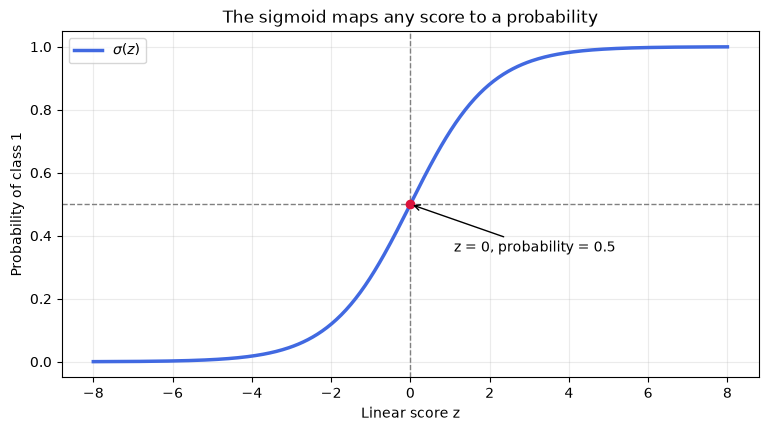

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z = np.linspace(-8, 8, 400)
plt.figure(figsize=(9, 4.5))
plt.plot(z, sigmoid(z), color="royalblue", linewidth=2.5, label=r"$\sigma(z)$")
plt.axhline(0.5, color="gray", linestyle="--", linewidth=1)
plt.axvline(0, color="gray", linestyle="--", linewidth=1)
plt.scatter([0], [0.5], color="crimson", zorder=3)
plt.annotate("z = 0, probability = 0.5", (0, 0.5), xytext=(1.1, 0.35),
             arrowprops={"arrowstyle": "->"})
plt.xlabel("Linear score z")
plt.ylabel("Probability of class 1")
plt.title("The sigmoid maps any score to a probability")
plt.ylim(-0.05, 1.05)
plt.grid(alpha=0.25)
plt.legend()
plt.show()


## 3. A small worked example

Suppose a model predicts whether a customer will churn using only the number of support calls. Let:

$$
\beta_0=-3, \qquad \beta_1=0.8, \qquad x=4
$$

The linear score is:

$$
z = -3 + 0.8(4) = 0.2
$$

The probability is:

$$
\hat{p}(y=1\mid x=4) = \sigma(0.2) \approx 0.550
$$

With a threshold of 0.5, this customer is classified as class 1 (likely to churn). With a threshold of 0.7, the same customer would be classified as class 0. This illustrates why a probability and a class label are different outputs.


In [2]:
beta_0, beta_1, x = -3, 0.8, 4
z = beta_0 + beta_1 * x
probability = sigmoid(z)
print(f"Linear score z: {z:.2f}")
print(f"Predicted probability: {probability:.3f}")
print(f"Class at threshold 0.5: {int(probability >= 0.5)}")
print(f"Class at threshold 0.7: {int(probability >= 0.7)}")


Linear score z: 0.20
Predicted probability: 0.550
Class at threshold 0.5: 1
Class at threshold 0.7: 0


## 4. Interpreting coefficients: log-odds and odds ratios

The sigmoid can be rearranged to show what the linear score means:

$$
\log\left(\frac{p}{1-p}\right) = \beta_0 + \beta_1x_1 + \cdots + \beta_px_p
$$

The left side is the **log-odds** (also called the logit). A one-unit increase in $x_j$ changes the log-odds by $\beta_j$, while keeping the other features fixed.

Exponentiating gives the **odds ratio**:

$$
\text{odds ratio}_j = e^{\beta_j}
$$

For example, if $\beta_j=0.8$, then $e^{0.8}\approx2.23$: a one-unit increase multiplies the odds of class 1 by about 2.23. This is an odds interpretation, not a direct 2.23-times increase in probability.


## 5. How the model learns

For each observation, the model produces a probability $\hat{p}_i$. It learns coefficients by minimizing the binary cross-entropy (log loss):

$$
J(\beta) = -\frac{1}{n}\sum_{i=1}^{n}\left[y_i\log(\hat{p}_i) + (1-y_i)\log(1-\hat{p}_i)\right]
$$

A confident correct prediction has a small loss. A confident incorrect prediction has a large loss, which encourages the model to produce calibrated probabilities.

In practice, scikit-learn optimizes this objective numerically. Regularization is commonly added to discourage unnecessarily large coefficients:

$$
J_{\text{regularized}} = J(\beta) + \lambda R(\beta)
$$

L2 regularization uses $R(\beta)=\sum_j\beta_j^2$; L1 regularization uses $R(\beta)=\sum_j|\beta_j|$ and can drive some coefficients to zero.


## 6. End-to-end example: two features and a decision boundary

The synthetic dataset below makes the geometry visible. Each point has two features and belongs to one of two classes. We split the data before fitting so that the test score measures generalization to unseen examples.


In [3]:
import pandas as pd
import seaborn as sns
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, log_loss, roc_auc_score,
                             roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

X, y = make_classification(
    n_samples=500,
    n_features=2,
    n_redundant=0,
    n_informative=2,
    n_clusters_per_class=1,
    class_sep=1.35,
    random_state=42,
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=1.0, max_iter=1000, random_state=42),
)
model.fit(X_train, y_train)

test_probability = model.predict_proba(X_test)[:, 1]
test_prediction = (test_probability >= 0.5).astype(int)
print(f"Accuracy: {accuracy_score(y_test, test_prediction):.3f}")
print(f"Log loss: {log_loss(y_test, test_probability):.3f}")
print(f"ROC-AUC: {roc_auc_score(y_test, test_probability):.3f}")
print(classification_report(y_test, test_prediction))


Accuracy: 0.944
Log loss: 0.158
ROC-AUC: 0.992
              precision    recall  f1-score   support

           0       0.97      0.92      0.94        62
           1       0.92      0.97      0.95        63

    accuracy                           0.94       125
   macro avg       0.95      0.94      0.94       125
weighted avg       0.95      0.94      0.94       125



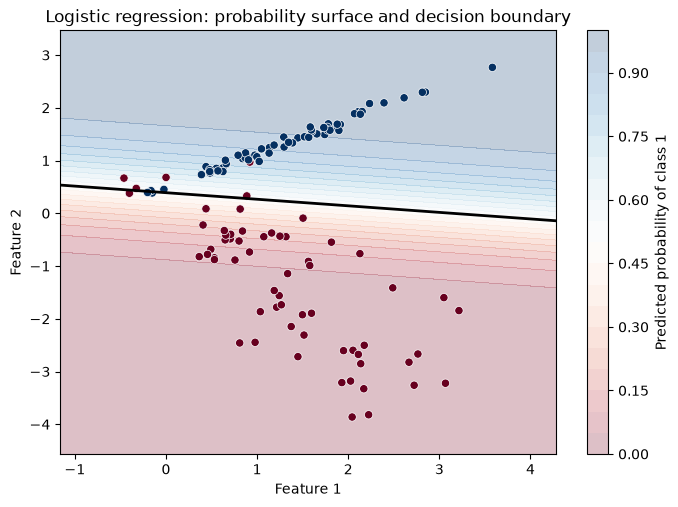

In [4]:
def plot_decision_boundary(estimator, X_data, y_data, title):
    x_min, x_max = X_data[:, 0].min() - 0.7, X_data[:, 0].max() + 0.7
    y_min, y_max = X_data[:, 1].min() - 0.7, X_data[:, 1].max() + 0.7
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300),
    )
    grid_probability = estimator.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1]
    grid_probability = grid_probability.reshape(xx.shape)

    plt.figure(figsize=(8, 5.5))
    contour = plt.contourf(xx, yy, grid_probability, levels=20, cmap="RdBu", alpha=0.25)
    plt.contour(xx, yy, grid_probability, levels=[0.5], colors="black", linewidths=2)
    plt.scatter(X_data[:, 0], X_data[:, 1], c=y_data, cmap="RdBu", edgecolor="white", linewidth=0.5)
    plt.colorbar(contour, label="Predicted probability of class 1")
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.title(title)
    plt.show()

plot_decision_boundary(model, X_test, y_test, "Logistic regression: probability surface and decision boundary")


## 7. Evaluating classification predictions

The confusion matrix separates predictions into four outcomes:

| | Actual 0 | Actual 1 |
|---|---:|---:|
| **Predicted 0** | True negative (TN) | False negative (FN) |
| **Predicted 1** | False positive (FP) | True positive (TP) |

Important metrics are:

$$
\text{accuracy}=\frac{TP+TN}{TP+TN+FP+FN}
\qquad
\text{precision}=\frac{TP}{TP+FP}
$$

$$
\text{recall}=\frac{TP}{TP+FN}
\qquad
F_1=2\cdot\frac{\text{precision}\cdot\text{recall}}{\text{precision}+\text{recall}}
$$

Accuracy can be misleading for imbalanced classes. Use precision, recall, F1, ROC-AUC, or precision-recall curves according to the real cost of each error.


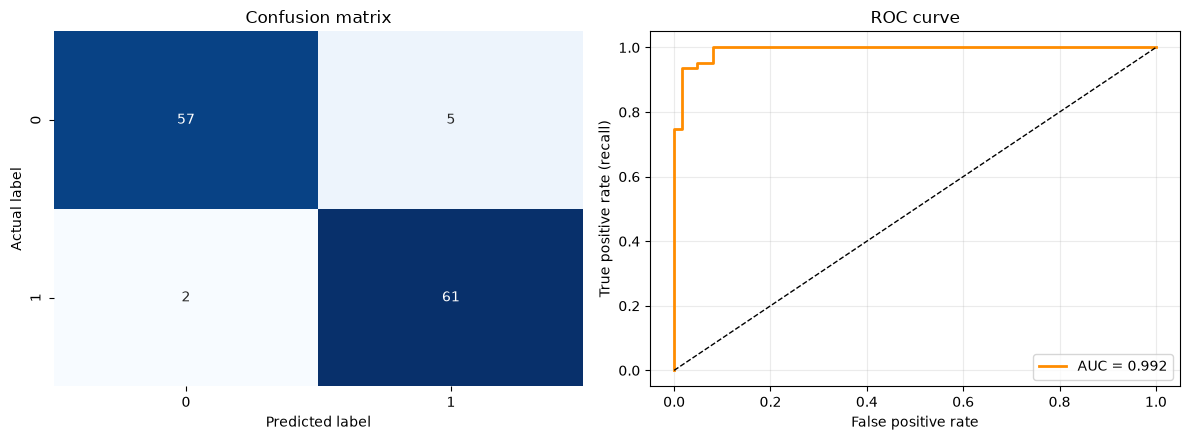

In [5]:
matrix = confusion_matrix(y_test, test_prediction)
fpr, tpr, thresholds = roc_curve(y_test, test_probability)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0])
axes[0].set_title("Confusion matrix")
axes[0].set_xlabel("Predicted label")
axes[0].set_ylabel("Actual label")

axes[1].plot(fpr, tpr, color="darkorange", linewidth=2, label=f"AUC = {roc_auc_score(y_test, test_probability):.3f}")
axes[1].plot([0, 1], [0, 1], "k--", linewidth=1)
axes[1].set_title("ROC curve")
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate (recall)")
axes[1].legend()
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()


## 8. The threshold is a decision, not a training parameter

The model estimates probabilities. We choose a threshold to turn those probabilities into labels:

$$
\hat{y} =
\begin{cases}
1 & \text{if } \hat{p}(y=1\mid x) \ge t\\
0 & \text{otherwise}
\end{cases}
$$

A lower threshold usually increases recall and false positives. A higher threshold usually increases precision and false negatives. The best threshold depends on the application: missing a disease, approving a fraudulent transaction, and sending a marketing email do not have the same costs.


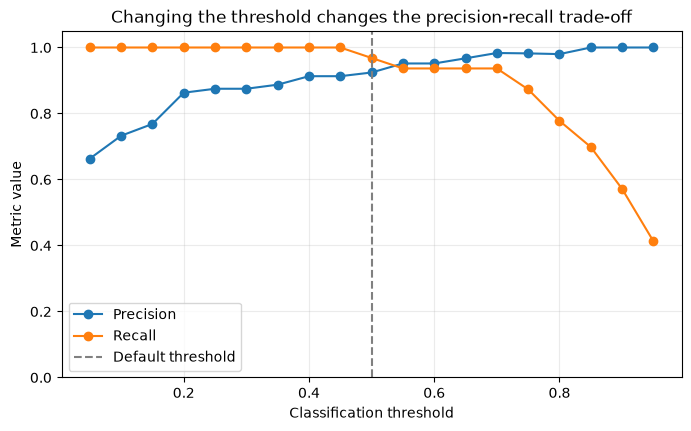

In [6]:
from sklearn.metrics import precision_score, recall_score
threshold_values = np.linspace(0.05, 0.95, 19)
precisions = [precision_score(y_test, test_probability >= t, zero_division=0) for t in threshold_values]
recalls = [recall_score(y_test, test_probability >= t) for t in threshold_values]
plt.figure(figsize=(8, 4.5))
plt.plot(threshold_values, precisions, marker="o", label="Precision")
plt.plot(threshold_values, recalls, marker="o", label="Recall")
plt.axvline(0.5, color="gray", linestyle="--", label="Default threshold")
plt.xlabel("Classification threshold")
plt.ylabel("Metric value")
plt.title("Changing the threshold changes the precision-recall trade-off")
plt.ylim(0, 1.05)
plt.grid(alpha=0.25)
plt.legend()
plt.show()


## 9. Practical guidance and limitations

### Good practices
1. **Split before fitting** and use stratification for imbalanced binary targets.
2. **Scale numeric features** when regularization is used or when feature magnitudes differ; a pipeline prevents leakage.
3. **Encode categorical variables** with an appropriate preprocessing step; do not assign arbitrary numeric order to nominal categories.
4. **Inspect probabilities**, not only labels. Calibration matters when probabilities drive decisions.
5. **Tune the threshold on validation data**, then report final performance on an untouched test set.

### Limitations
- The standard model creates a linear decision boundary in feature space.
- Strongly correlated features can make individual coefficient interpretations unstable.
- Outliers and mislabeled examples can influence the fitted coefficients.
- A high accuracy score does not prove that the probabilities are calibrated or that the model is fair.
- For non-linear patterns, consider feature engineering or models such as trees and kernel methods.

## Takeaway

Logistic regression combines a linear predictor with the sigmoid function to estimate class probabilities. The coefficients explain changes in log-odds, the loss function trains the model, and the threshold converts probabilities into actions. Always evaluate the model with metrics and thresholds that match the real problem.


## 10. The complete logistic-regression model

A logistic-regression model is a sequence of three connected transformations:

### Step 1: calculate the linear score

For features $x_1, x_2, \ldots, x_p$, the model computes:

$$
z = \beta_0 + \beta_1x_1 + \beta_2x_2 + \cdots + \beta_px_p
$$

The intercept $\beta_0$ is the score when all features are zero. Each coefficient $\beta_j$ changes the score, and therefore the log-odds, when feature $x_j$ increases by one unit while the other features stay fixed.

### Step 2: convert the score to a probability

$$
\hat{p}(y=1\mid x) = \sigma(z) = \frac{1}{1+e^{-z}}
$$

Equivalently, logistic regression is linear in the log-odds:

$$
\log\left(\frac{\hat{p}}{1-\hat{p}}\right)=z
$$

### Step 3: convert the probability to a class

For a selected threshold $t$:

$$
\hat{y} =
\begin{cases}
1 & \text{if } \hat{p} \ge t\\
0 & \text{if } \hat{p} < t
\end{cases}
$$

At the default threshold $t=0.5$, the decision boundary is $z=0$, because $\sigma(0)=0.5$. With two features, the boundary is the line:

$$
\beta_0+\beta_1x_1+\beta_2x_2=0
\qquad\Longrightarrow\qquad
x_2=-\frac{\beta_0+\beta_1x_1}{\beta_2}
$$

The coefficients are learned by minimizing binary cross-entropy:

$$
J(\beta)=-\frac{1}{n}\sum_{i=1}^{n}\left[y_i\log(\hat{p}_i)+(1-y_i)\log(1-\hat{p}_i)\right]
$$

The complete flow is therefore:

$$
\text{features} \longrightarrow z \longrightarrow \hat{p} \longrightarrow \hat{y}
$$


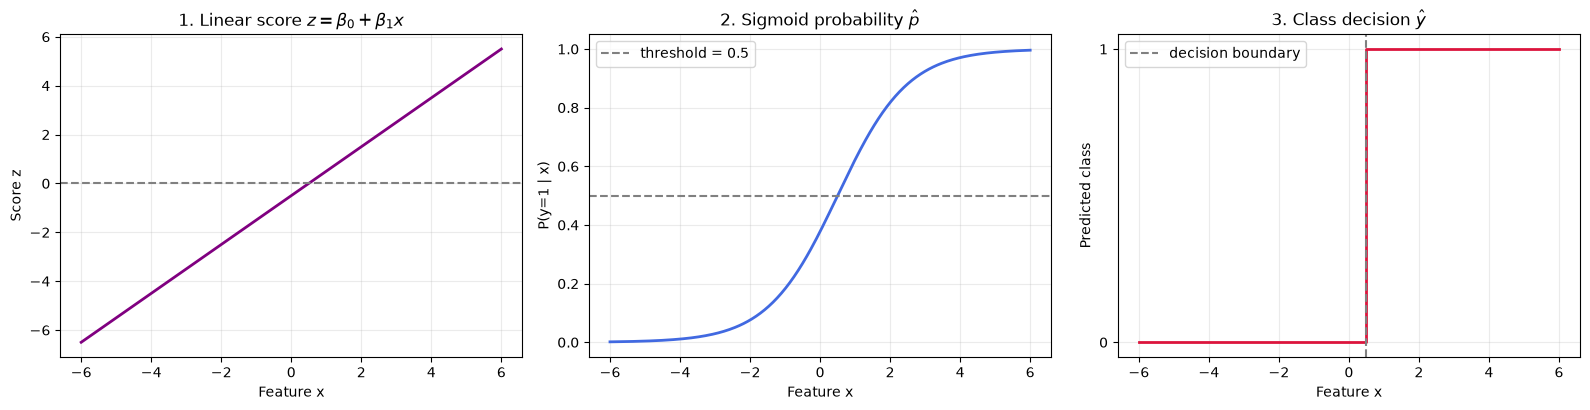

In [7]:
# Visualize the three stages: score, probability, and class decision.
example_x = np.linspace(-6, 6, 300)
example_beta_0, example_beta_1 = -0.5, 1.0
example_z = example_beta_0 + example_beta_1 * example_x
example_probability = sigmoid(example_z)
example_class = (example_probability >= 0.5).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].plot(example_x, example_z, color="purple", linewidth=2)
axes[0].axhline(0, color="gray", linestyle="--")
axes[0].set_title(r"1. Linear score $z=\beta_0+\beta_1x$")
axes[0].set_xlabel("Feature x")
axes[0].set_ylabel("Score z")
axes[0].grid(alpha=0.25)

axes[1].plot(example_x, example_probability, color="royalblue", linewidth=2)
axes[1].axhline(0.5, color="gray", linestyle="--", label="threshold = 0.5")
axes[1].set_title(r"2. Sigmoid probability $\hat{p}$")
axes[1].set_xlabel("Feature x")
axes[1].set_ylabel("P(y=1 | x)")
axes[1].set_ylim(-0.05, 1.05)
axes[1].legend()
axes[1].grid(alpha=0.25)

axes[2].step(example_x, example_class, where="mid", color="crimson", linewidth=2)
axes[2].axvline(-example_beta_0 / example_beta_1, color="gray", linestyle="--", label="decision boundary")
axes[2].set_title(r"3. Class decision $\hat{y}$")
axes[2].set_xlabel("Feature x")
axes[2].set_ylabel("Predicted class")
axes[2].set_yticks([0, 1])
axes[2].legend()
axes[2].grid(alpha=0.25)

plt.tight_layout()
plt.show()


### Reading the visualization

The first plot shows the unrestricted linear score. The second shows how the sigmoid compresses that score into a probability. The third applies the threshold and creates the final class prediction. The probability contains more information than the class label, so keep it when ranking risk or selecting a threshold based on real-world costs.


## 11. Cost function: how the model learns its weights

The **cost function** tells us how wrong the model is. In logistic regression, it is usually called **log loss** or **binary cross-entropy**.

For one training example, the loss is:

$$
L(y,p)=-\left[y\log(p)+(1-y)\log(1-p)\right]
$$

Here, $y$ is the real answer (`0` or `1`) and $p$ is the predicted probability of class 1.

### Why does the logarithm matter?

If the real answer is $y=1$, the formula becomes:

$$
L(1,p)=-\log(p)
$$

If the model predicts $p=0.9$, the loss is small. If it predicts $p=0.01$, the loss is very large. Therefore, the logarithm strongly punishes confident wrong predictions.

If the real answer is $y=0$, the formula becomes:

$$
L(0,p)=-\log(1-p)
$$

The average cost over all $n$ examples is:

$$
J(\beta)=-\frac{1}{n}\sum_{i=1}^{n}\left[y_i\log(p_i)+(1-y_i)\log(1-p_i)\right]
$$

### How does this train the weights?

The model changes the weights in the direction that makes $J(\beta)$ smaller. The gradient for weight $\beta_j$ is:

$$
\frac{\partial J}{\partial\beta_j}=
\frac{1}{n}\sum_{i=1}^{n}(p_i-y_i)x_{ij}
$$

Then gradient descent updates each weight:

$$
\beta_j \leftarrow \beta_j-\alpha\frac{\partial J}{\partial\beta_j}
$$

where $\alpha$ is the learning rate. The training loop is:

1. Use the current weights to calculate $z$ and $p$.
2. Calculate the log loss.
3. Calculate the gradient.
4. Move the weights slightly to reduce the loss.
5. Repeat until the loss stops improving.

The logarithm is important because it creates a smooth, meaningful penalty: correct confident predictions get low cost, while confident wrong predictions get high cost. The optimizer uses that cost and its gradient to learn the weights.


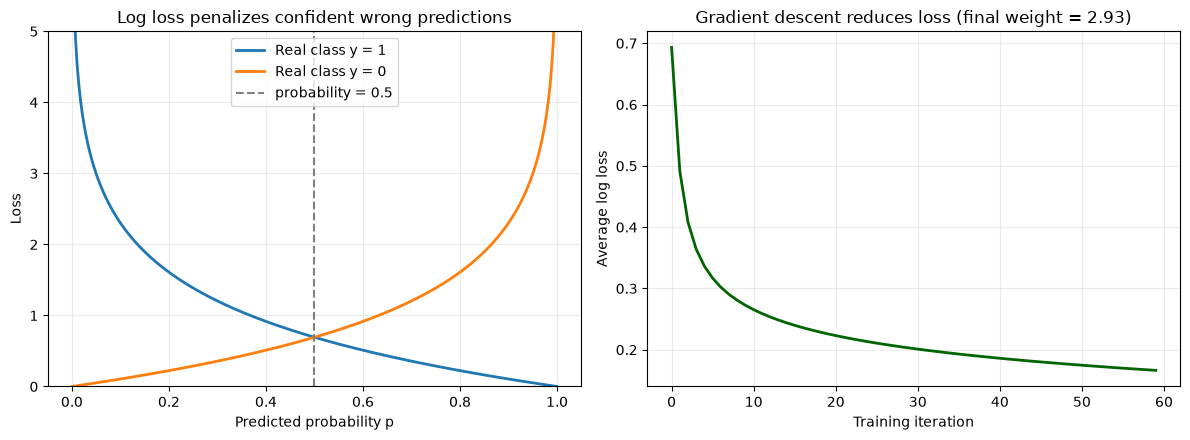

In [8]:
# Visualize how log loss treats correct and incorrect probabilities.
probabilities = np.linspace(0.001, 0.999, 300)
loss_when_zero = -np.log(1 - probabilities)
loss_when_one = -np.log(probabilities)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(probabilities, loss_when_one, label="Real class y = 1", linewidth=2)
axes[0].plot(probabilities, loss_when_zero, label="Real class y = 0", linewidth=2)
axes[0].axvline(0.5, color="gray", linestyle="--", label="probability = 0.5")
axes[0].set_xlabel("Predicted probability p")
axes[0].set_ylabel("Loss")
axes[0].set_title("Log loss penalizes confident wrong predictions")
axes[0].set_ylim(0, 5)
axes[0].grid(alpha=0.25)
axes[0].legend()

# A one-feature example: gradient descent learns a weight and intercept.
x_train = np.array([-2.0, -1.0, 0.5, 1.0, 2.0])
y_train = np.array([0, 0, 0, 1, 1])
weight, bias = 0.0, 0.0
learning_rate = 0.8
loss_history = []

for _ in range(60):
    p_train = sigmoid(bias + weight * x_train)
    loss = -np.mean(y_train * np.log(p_train) + (1 - y_train) * np.log(1 - p_train))
    loss_history.append(loss)
    error = p_train - y_train
    bias -= learning_rate * np.mean(error)
    weight -= learning_rate * np.mean(error * x_train)

axes[1].plot(loss_history, color="darkgreen", linewidth=2)
axes[1].set_xlabel("Training iteration")
axes[1].set_ylabel("Average log loss")
axes[1].set_title(f"Gradient descent reduces loss (final weight = {weight:.2f})")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()


## 12. Why the logarithm is perfect for logistic regression

The logarithm turns probabilities into a useful penalty. For a real class of $y=1$, the loss is:

$$
L(1,p)=-\log(p)
$$

For a real class of $y=0$, the loss is:

$$
L(0,p)=-\log(1-p)
$$

The correct prediction has a small loss, while a confident wrong prediction has a very large loss. For example, when the true class is 1, predicting $p=0.99$ is rewarded with a loss close to zero, but predicting $p=0.01$ is heavily penalized.

The logarithmic loss is a particularly good match for logistic regression because:

1. **It works directly with probabilities.** A prediction of 0.9 is treated as more informative than a prediction of 0.6.
2. **It strongly punishes confident mistakes.** This prevents the model from being confidently wrong.
3. **It is smooth and differentiable.** Gradient-based optimizers can use its slope to update the weights.
4. **It comes from probability theory.** Minimizing average log loss is equivalent to maximizing the likelihood of the observed binary labels.
5. **It matches the sigmoid output.** The sigmoid produces values between 0 and 1, exactly the range required by the logarithm in the binary cross-entropy formula.


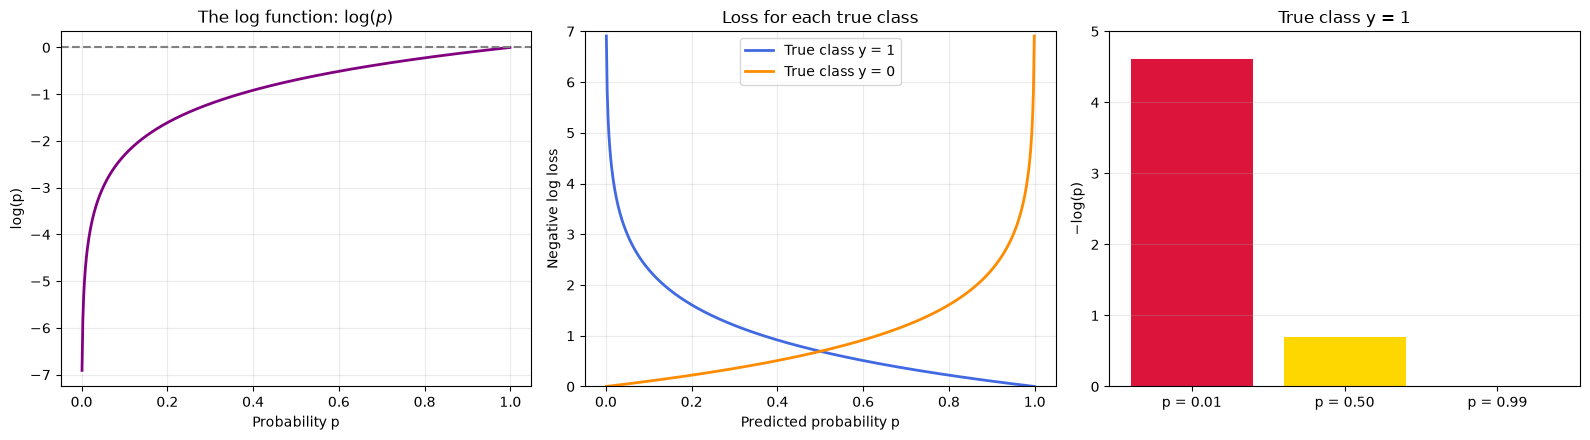

In [9]:
probability_grid = np.linspace(0.001, 0.999, 500)
log_probability = np.log(probability_grid)
loss_for_class_one = -np.log(probability_grid)
loss_for_class_zero = -np.log(1 - probability_grid)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].plot(probability_grid, log_probability, color="purple", linewidth=2)
axes[0].axhline(0, color="gray", linestyle="--")
axes[0].set_title(r"The log function: $\log(p)$")
axes[0].set_xlabel("Probability p")
axes[0].set_ylabel("log(p)")
axes[0].grid(alpha=0.25)

axes[1].plot(probability_grid, loss_for_class_one, color="royalblue", linewidth=2, label="True class y = 1")
axes[1].plot(probability_grid, loss_for_class_zero, color="darkorange", linewidth=2, label="True class y = 0")
axes[1].set_title("Loss for each true class")
axes[1].set_xlabel("Predicted probability p")
axes[1].set_ylabel("Negative log loss")
axes[1].set_ylim(0, 7)
axes[1].grid(alpha=0.25)
axes[1].legend()

example_probabilities = np.array([0.01, 0.5, 0.99])
example_losses = -np.log(example_probabilities)
axes[2].bar(["p = 0.01", "p = 0.50", "p = 0.99"], example_losses, color=["crimson", "gold", "seagreen"])
axes[2].set_title("True class y = 1")
axes[2].set_ylabel("−log(p)")
axes[2].set_ylim(0, 5)
axes[2].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()
